# R1_A - Animal-held-out discrimination
Run preprocessing 00 first, then execute cells from top to bottom. Each analysis cell reports the data or results it produced. Responsive is the positive class; selection, feature scaling, and probability calibration use training animals only.

**Evaluation paths:** the existing primary analysis fits a separate scalar model within each LOAO training fold, then pools the held-out probabilities for ROC-AUC and PR-AUC. The raw fold-specific Omega values are also retained so that pooled raw-Omega scores and fold-level raw-Omega scores can be evaluated separately below. These are distinct scoring strategies and should not be conflated.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'hoi_anesthesia').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the repository.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from src.hoi_anesthesia.io import load_covariance_dict
from sklearn.metrics import average_precision_score, roc_auc_score
from src.hoi_anesthesia.validation import (
    LOAOCheckpointStore, LOAOResult, SearchSettings, build_loao_manifest,
    configure_loao_logger, load_classification_data, loao_run_id,
    run_loao_annealing, run_loao_exhaustive, save_loao_result,
    evaluate_feature_sets, save_feature_evaluation,
)

print(f'Repository root: {ROOT}')
print(f'Available compute device: {"CUDA" if torch.cuda.is_available() else "CPU"}')

Repository root: c:\CAMILO\Brain_Entropy\CODES\high-order-anesthesia
Available compute device: CUDA


c:\CAMILO\venvs\.high-order-anesthesia_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Search methods
**Exhaustive search (orders 3, 4, 5):** score every regional combination in batches of 2,048 and retain the best animal-balanced training ROC-AUC in each direction. With 82 regions this evaluates 88,560, 1,749,060, and 27,285,336 candidates, respectively.

**Simulated annealing (orders 6, 7, 8, 9):** search the larger spaces with 100 restarts, up to 10,000 iterations, and early stopping after 1,000 iterations without a strict improvement. Both Omega and FC use the same annealing implementation. The separate order-5 benchmark compares both methods on training folds only.

Both methods optimize the same fold-specific, animal-balanced ROC-AUC; responsive is positive. Exact objective ties use the lexicographically first n-plet. Each search cell displays the selected n-plets and training objective after the search completes.

**Selection measures (`SEARCH_MEASURES`):** raw Omega `omega` (O), normalized Omega `omega_norm` (O/S, with S = TC + DTC >= |O|, so O/S lies in [-1, 1] and is insensitive to overall dependence strength), and mean within-n-plet Fisher-z FC `fc`. All three use identical folds, settings and seeds.

In [2]:
SETTINGS = SearchSettings(restarts=100, iterations=20000, early_stop=1000,
                          temperature=0.05, cooling=0.99, batch_size=8000, seed=2026)
EXHAUSTIVE_ORDERS = (3, 4, 5)
ANNEALING_ORDERS = (6, 7, 8, 9)
DATASETS = ('MA', 'DBS')
SEARCH_MEASURES = ('omega', 'omega_norm', 'fc')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
COVARIANCE_PATH = ROOT / 'data' / 'covariance_matrices_gc.h5'
METADATA_PATH = ROOT / 'data' / 'scan_metadata.csv'
OUTPUT = ROOT / 'results' / 'R1_A_loao'
RUN_MANIFEST = build_loao_manifest(
    COVARIANCE_PATH, METADATA_PATH, SETTINGS, DATASETS, DEVICE,
)
RUN_ID = loao_run_id(RUN_MANIFEST)
CHECKPOINT_DIR = OUTPUT / 'checkpoints' / RUN_ID
CHECKPOINTS = LOAOCheckpointStore(CHECKPOINT_DIR, RUN_MANIFEST)
LOGGER = configure_loao_logger(CHECKPOINT_DIR / 'run.log')
LOGGER.info('R1 run_id=%s device=%s datasets=%s', RUN_ID, DEVICE, DATASETS)
LOGGER.info('Run manifest: %s', RUN_MANIFEST)
print(f'Run ID: {RUN_ID}')
print(f'Datasets: {DATASETS}; exhaustive orders: {EXHAUSTIVE_ORDERS}; annealing orders: {ANNEALING_ORDERS}')
display(pd.Series(RUN_MANIFEST['settings'], name='Search setting').to_frame())

2026-11-10 16:04:13,255 INFO R1 run_id=fb5e6bba2d253fd2fdfa device=cuda datasets=('MA', 'DBS')
2026-11-10 16:04:13,255 INFO Run manifest: {'checkpoint_schema': 1, 'algorithm_version': 1, 'inputs': {'covariance_sha256': 'b72d47513317a87f8778f0076775ca31f3bb5dd7e602f385bf3ec6bd2ff6be09', 'metadata_sha256': '3346544edbb3d1500e4d87451c642eea5c1766de0e7166b2b432ce4935091e96'}, 'settings': {'restarts': 100, 'iterations': 20000, 'early_stop': 1000, 'temperature': 0.05, 'cooling': 0.99, 'batch_size': 8000, 'seed': 2026}, 'datasets': ['MA', 'DBS'], 'device': 'cuda', 'orders': {'exhaustive': [3, 4, 5], 'annealing': [6, 7, 8, 9]}}


Run ID: fb5e6bba2d253fd2fdfa
Datasets: ('MA', 'DBS'); exhaustive orders: (3, 4, 5); annealing orders: (6, 7, 8, 9)


,Search setting
restarts,100.00
iterations,20000.00
early_stop,1000.00
temperature,0.05
cooling,0.99
batch_size,8000.00
seed,2026.00


In [3]:
metadata = pd.read_csv(METADATA_PATH, dtype={'animal': str, 'session': str, 'run': str})
all_covariances = load_covariance_dict(COVARIANCE_PATH)
inputs = {}
input_summaries = []
for dataset in DATASETS:
    covariances, scans = load_classification_data(all_covariances, metadata, dataset)
    inputs[dataset] = (covariances, scans)
    input_summaries.append(scans.groupby(['dataset', 'animal', 'state'], as_index=False).agg(
        scans=('scan_index', 'size'), sessions=('session', 'nunique')))
    print(f'{dataset}: covariance shape={covariances.shape}; scans={len(scans)}; regions={covariances.shape[1]}')
display(pd.concat(input_summaries, ignore_index=True))

MA: covariance shape=(80, 82, 82); scans=80; regions=82
DBS: covariance shape=(100, 82, 82); scans=100; regions=82


,dataset,animal,state,scans,sessions
0,MA,A,MA_awake,2,1
1,MA,J,MA_awake,14,7
2,MA,J,deep_propofol,4,3
3,MA,K,MA_awake,8,8
4,MA,K,deep_propofol,8,5
5,MA,K,ketamine,8,4
6,MA,L,ketamine,6,4
7,MA,L,ts_selv4,2,2
8,MA,R,deep_propofol,11,6
9,MA,R,ketamine,8,6


## Optional GPU smoke pass
Run this after the inputs cell and before the full search. It scores one exhaustive candidate batch for each order and runs one annealing iteration per restart on the first training fold of each dataset. It does not evaluate held-out scans or save results.

In [4]:
# from src.hoi_anesthesia.validation import (
#     TrainingObjective, candidate_batches, loao_folds,
#     simulated_annealing_search,
# )

# if DEVICE != 'cuda':
#     raise RuntimeError('CUDA is unavailable; select a CUDA-enabled PyTorch environment.')

# SMOKE_SETTINGS = SearchSettings(
#     restarts=100, iterations=1, early_stop=1, temperature=0.05,
#     cooling=0.99, batch_size=SETTINGS.batch_size, seed=SETTINGS.seed,
# )
# objective = candidates = None
# torch.cuda.synchronize(DEVICE)
# torch.cuda.empty_cache()
# torch.cuda.reset_peak_memory_stats(DEVICE)
# try:
#     for dataset, (covariances, scans) in inputs.items():
#         _, train, _ = next(iter(loao_folds(scans)))
#         train_rows = scans.iloc[train]
#         labels = train_rows['responsive'].to_numpy()
#         for measure in ('omega', 'fc'):
#             objective = TrainingObjective(
#                 covariances[train], labels, train_rows['animal'],
#                 measure, DEVICE, SMOKE_SETTINGS.batch_size,
#             )
#             for order in EXHAUSTIVE_ORDERS:
#                 batch = next(candidate_batches(
#                     covariances.shape[-1], order, SMOKE_SETTINGS.batch_size,
#                 ))
#                 candidates = torch.tensor(batch, dtype=torch.long, device=DEVICE)
#                 objective(candidates, polarity=1)
#                 objective(candidates, polarity=-1)
#                 candidates = None
#             for order in ANNEALING_ORDERS:
#                 simulated_annealing_search(
#                     objective, order, SMOKE_SETTINGS,
#                     SMOKE_SETTINGS.seed + order * 2,
#                 )
#             objective = None
# finally:
#     torch.cuda.synchronize(DEVICE)
#     peak_memory = torch.cuda.max_memory_allocated(DEVICE) / 1024**2
#     objective = candidates = None
#     torch.cuda.empty_cache()
# print(f'Peak allocated CUDA memory: {peak_memory:.1f} MiB')
# print(f'Allocated after cleanup: {torch.cuda.memory_allocated(DEVICE) / 1024**2:.1f} MiB')

## Outer LOAO
Each fold selects both polarities for every measure in `SEARCH_MEASURES` (O, O/S and mean within-n-plet Fisher-z FC). Each selected set gets scalar calibration, and FC selections also a full pairwise-vector L2 model (C=1), with weighted training-only scaling/fitting. The feature-set evaluation at the end refits four probability models on every O- and O/S-selected n-plet. Weights total one per class. No test-fold AUC or held-out tuning.

Completed dataset/animal/order/measure units are checkpointed under `results/R1_A_loao/checkpoints/<run-id>/`; `run.log` records progress and full tracebacks. After an interruption, restart the kernel, then rerun setup, settings, inputs and the affected search cell. Matching checkpoints are reused; changed covariance/metadata inputs or search settings use a different run ID. Run the save/summary cells after both search stages finish.

### 1. Exhaustive search: n = 3, 4, 5
Evaluate every regional combination in each training fold.

In [5]:
exhaustive_results = {}
for dataset, (covariances, scans) in inputs.items():
    exhaustive_results[dataset] = run_loao_exhaustive(
        covariances, scans, settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER, measures=SEARCH_MEASURES,
    )

exhaustive_selections = pd.concat(
    [result.selections for result in exhaustive_results.values()], ignore_index=True,
)
print(f'Completed exhaustive selections: {len(exhaustive_selections)}')
display(exhaustive_selections[['dataset', 'held_out_animal', 'order', 'selection_measure',
                                'polarity', 'nplet', 'training_auc', 'method']])

2026-11-10 16:04:13,453 INFO Starting exhaustive dataset=MA held_out_animal=A n=3 measure=omega
2026-11-10 16:04:13,454 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=3 measure=omega
2026-11-10 16:04:13,454 INFO Starting exhaustive dataset=MA held_out_animal=A n=3 measure=omega_norm
2026-11-10 16:04:13,454 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=3 measure=omega_norm
2026-11-10 16:04:13,455 INFO Starting exhaustive dataset=MA held_out_animal=A n=3 measure=fc
2026-11-10 16:04:13,456 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=3 measure=fc
2026-11-10 16:04:13,456 INFO MA | held-out animal A | exhaustive n=3 complete
2026-11-10 16:04:13,456 INFO Starting exhaustive dataset=MA held_out_animal=A n=4 measure=omega
2026-11-10 16:04:13,457 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=4 measure=omega
2026-11-10 16:04:13,457 INFO Starting exhaustive dataset=MA held_out_animal=A n=4 measure=omega_no

Completed exhaustive selections: 180


,dataset,held_out_animal,order,selection_measure,polarity,nplet,training_auc,method
0,MA,A,3,omega,1,"[26, 68, 78]",0.996094,exhaustive
1,MA,A,3,omega,-1,"[23, 34, 81]",0.954401,exhaustive
2,MA,A,3,omega_norm,1,"[27, 69, 70]",0.985332,exhaustive
3,MA,A,3,omega_norm,-1,"[12, 27, 63]",0.944356,exhaustive
4,MA,A,3,fc,1,"[6, 15, 27]",1.000000,exhaustive
...,...,...,...,...,...,...,...,...
175,DBS,Y,5,omega,-1,"[6, 13, 21, 47, 66]",0.958664,exhaustive
176,DBS,Y,5,omega_norm,1,"[6, 12, 19, 52, 69]",1.000000,exhaustive
177,DBS,Y,5,omega_norm,-1,"[0, 21, 28, 57, 70]",0.900198,exhaustive
178,DBS,Y,5,fc,1,"[1, 6, 9, 24, 32]",1.000000,exhaustive


### 2. Simulated annealing: n = 6, 7, 8, 9
Run the shared annealer on the larger candidate spaces.

In [6]:
annealing_results = {}
for dataset, (covariances, scans) in inputs.items():
    annealing_results[dataset] = run_loao_annealing(
        covariances, scans, settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER, measures=SEARCH_MEASURES,
    )

annealing_selections = pd.concat(
    [result.selections for result in annealing_results.values()], ignore_index=True,
)
print(f'Completed simulated-annealing selections: {len(annealing_selections)}')
display(annealing_selections[['dataset', 'held_out_animal', 'order', 'selection_measure',
                               'polarity', 'nplet', 'training_auc', 'method']])

2026-11-10 16:04:13,631 INFO Starting annealing dataset=MA held_out_animal=A n=6 measure=omega
2026-11-10 16:04:13,632 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=6 measure=omega
2026-11-10 16:04:13,632 INFO Starting annealing dataset=MA held_out_animal=A n=6 measure=omega_norm
2026-11-10 16:04:13,632 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=6 measure=omega_norm
2026-11-10 16:04:13,633 INFO Starting annealing dataset=MA held_out_animal=A n=6 measure=fc
2026-11-10 16:04:13,633 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=6 measure=fc
2026-11-10 16:04:13,633 INFO MA | held-out animal A | annealing n=6 complete
2026-11-10 16:04:13,634 INFO Starting annealing dataset=MA held_out_animal=A n=7 measure=omega
2026-11-10 16:04:13,634 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=7 measure=omega
2026-11-10 16:04:13,634 INFO Starting annealing dataset=MA held_out_animal=A n=7 measure=omega_norm
2026-11

Completed simulated-annealing selections: 240


,dataset,held_out_animal,order,selection_measure,polarity,nplet,training_auc,method
0,MA,A,6,omega,1,"[1, 25, 28, 59, 64, 65]",1.000000,annealing
1,MA,A,6,omega,-1,"[0, 12, 18, 21, 59, 62]",0.964824,annealing
2,MA,A,6,omega_norm,1,"[22, 28, 29, 65, 67, 81]",1.000000,annealing
3,MA,A,6,omega_norm,-1,"[9, 12, 18, 52, 53, 68]",0.977838,annealing
4,MA,A,6,fc,1,"[1, 2, 15, 70, 76, 78]",1.000000,annealing
...,...,...,...,...,...,...,...,...
235,DBS,Y,9,omega,-1,"[4, 29, 42, 44, 53, 65, 73, 77, 79]",0.824868,annealing
236,DBS,Y,9,omega_norm,1,"(0, 7, 12, 44, 45, 46, 50, 67, 74)",1.000000,annealing
237,DBS,Y,9,omega_norm,-1,"(4, 42, 44, 53, 60, 65, 68, 73, 77)",0.816468,annealing
238,DBS,Y,9,fc,1,"(0, 1, 6, 8, 12, 20, 21, 59, 79)",1.000000,annealing


### Combine results and save

In [7]:
OUTPUT.mkdir(parents=True, exist_ok=True)
results = {}
for dataset in DATASETS:
    exhaustive = exhaustive_results[dataset]
    annealing = annealing_results[dataset]
    results[dataset] = LOAOResult(
        predictions=pd.concat([exhaustive.predictions, annealing.predictions], ignore_index=True),
        selections=pd.concat([exhaustive.selections, annealing.selections], ignore_index=True),
        metrics=pd.concat([exhaustive.metrics, annealing.metrics], ignore_index=True),
        stability=pd.concat([exhaustive.stability, annealing.stability], ignore_index=True),
        region_frequency=pd.concat([exhaustive.region_frequency, annealing.region_frequency], ignore_index=True),
        sessions=exhaustive.sessions,
        fits=pd.concat([exhaustive.fits, annealing.fits], ignore_index=True),
    )
    save_loao_result(results[dataset], OUTPUT, dataset)
    print(f'{dataset}: saved {len(results[dataset].predictions)} held-out predictions and '
          f'{len(results[dataset].selections)} fold selections to {OUTPUT}')

display(pd.DataFrame([
    {'dataset': dataset, 'predictions': len(result.predictions),
     'selections': len(result.selections), 'metrics': len(result.metrics)}
    for dataset, result in results.items()
]))

MA: saved 4480 held-out predictions and 210 fold selections to c:\CAMILO\Brain_Entropy\CODES\high-order-anesthesia\results\R1_A_loao
DBS: saved 5600 held-out predictions and 210 fold selections to c:\CAMILO\Brain_Entropy\CODES\high-order-anesthesia\results\R1_A_loao


,dataset,predictions,selections,metrics
0,MA,4480,210,56
1,DBS,5600,210,56


## Pooled out-of-fold probabilities
The primary probability analysis fits a separate model inside each training fold and pools only the held-out probabilities. ROC-AUC and PR-AUC (weighted average precision) use responsive as positive; animal-balanced weights give each class equal total weight. This avoids computing an AUC inside a held-out fold that contains only one class.

The cells below additionally evaluate raw Omega in two explicit ways: pool the oriented, held-out Omega values across folds, or calculate metrics separately within each held-out animal fold when both classes are present. Raw Omega is oriented using the polarity chosen on training data. Fold metrics are undefined when a held-out animal has only one class; DBS also has animal/state confounding. These raw-score analyses are additional comparisons, not substitutes for fold-specific probability calibration.

In [8]:
metrics = pd.concat([result.metrics for result in results.values()], ignore_index=True)
display(metrics)
display(pd.concat([result.stability for result in results.values()], ignore_index=True))
display(pd.concat([result.region_frequency for result in results.values()], ignore_index=True))
display(pd.concat([result.sessions for result in results.values()], ignore_index=True))

,dataset,order,selection_measure,polarity,model,roc_auc,pr_auc,weighted_prevalence,positive_class,n_scans
0,MA,3,fc,-1,pairwise_vector,0.961841,0.971484,0.5,responsive,80
1,MA,3,fc,-1,scalar,0.956952,0.970073,0.5,responsive,80
2,MA,3,fc,1,pairwise_vector,0.836403,0.857568,0.5,responsive,80
3,MA,3,fc,1,scalar,0.841358,0.859511,0.5,responsive,80
4,MA,3,omega,-1,scalar,0.650789,0.763738,0.5,responsive,80
...,...,...,...,...,...,...,...,...,...,...
107,DBS,9,fc,1,scalar,0.805285,0.832547,0.5,responsive,100
108,DBS,9,omega,-1,scalar,0.358774,0.515319,0.5,responsive,100
109,DBS,9,omega,1,scalar,0.644694,0.780321,0.5,responsive,100
110,DBS,9,omega_norm,-1,scalar,0.078410,0.324276,0.5,responsive,100


,dataset,order,selection_measure,polarity,animal_a,animal_b,jaccard
0,MA,3,fc,-1,A,J,0.000
1,MA,3,fc,-1,A,K,1.000
2,MA,3,fc,-1,A,L,1.000
3,MA,3,fc,-1,A,R,1.000
4,MA,3,fc,-1,J,K,0.000
...,...,...,...,...,...,...,...
835,DBS,9,omega_norm,1,J,T,0.200
836,DBS,9,omega_norm,1,J,Y,0.200
837,DBS,9,omega_norm,1,N,T,0.200
838,DBS,9,omega_norm,1,N,Y,0.125


,dataset,order,selection_measure,polarity,region,count,fraction
0,MA,3,fc,-1,0,0,0.0
1,MA,3,fc,-1,1,0,0.0
2,MA,3,fc,-1,2,0,0.0
3,MA,3,fc,-1,3,0,0.0
4,MA,3,fc,-1,4,0,0.0
...,...,...,...,...,...,...,...
6883,DBS,9,omega_norm,1,77,0,0.0
6884,DBS,9,omega_norm,1,78,0,0.0
6885,DBS,9,omega_norm,1,79,0,0.0
6886,DBS,9,omega_norm,1,80,0,0.0


,dataset,animal,state,n_sessions,n_scans
0,MA,A,MA_awake,1,2
1,MA,J,MA_awake,7,14
2,MA,J,deep_propofol,3,4
3,MA,K,MA_awake,8,8
4,MA,K,deep_propofol,5,8
5,MA,K,ketamine,4,8
6,MA,L,ketamine,4,6
7,MA,L,ts_selv4,2,2
8,MA,R,deep_propofol,6,11
9,MA,R,ketamine,6,8


### Retain out-of-fold raw Omega values
Each value below was calculated on a held-out scan using the n-plet selected without that animal. Keep the fold, n-plet, and training-selected polarity with every value; do not aggregate away these identifiers. This table supports both pooled raw-Omega evaluation and fold-specific evaluation.

In [9]:
predictions = pd.concat([result.predictions for result in results.values()], ignore_index=True)
omega_oof_predictions = predictions.loc[
    (predictions['selection_measure'] == 'omega')
    & (predictions['model'] == 'scalar')
].copy()
omega_oof_predictions = omega_oof_predictions.dropna(subset=['raw_omega']).copy()
omega_oof_predictions['omega_score'] = (
    omega_oof_predictions['polarity'] * omega_oof_predictions['raw_omega']
)
omega_oof_predictions['score_definition'] = 'training-selected polarity x held-out raw Omega'
omega_oof_path = OUTPUT / 'omega_oof_predictions.csv'
omega_oof_predictions.to_csv(omega_oof_path, index=False)
print(f'Saved {len(omega_oof_predictions)} fold-specific Omega scores to {omega_oof_path}')
display(omega_oof_predictions[
    ['dataset', 'held_out_animal', 'state', 'scan_index', 'responsive', 'order',
     'polarity', 'nplet', 'raw_omega', 'omega_score']
].head(12))

Saved 2520 fold-specific Omega scores to c:\CAMILO\Brain_Entropy\CODES\high-order-anesthesia\results\R1_A_loao\omega_oof_predictions.csv


,dataset,held_out_animal,state,scan_index,responsive,order,polarity,nplet,raw_omega,omega_score
0,MA,A,MA_awake,0,1,3,1,"[26, 68, 78]",-0.059402,-0.059402
1,MA,A,MA_awake,1,1,3,1,"[26, 68, 78]",-0.030499,-0.030499
2,MA,A,MA_awake,0,1,3,-1,"[23, 34, 81]",-0.410427,0.410427
3,MA,A,MA_awake,1,1,3,-1,"[23, 34, 81]",-0.341765,0.341765
16,MA,A,MA_awake,0,1,4,1,"[7, 27, 29, 69]",0.177936,0.177936
17,MA,A,MA_awake,1,1,4,1,"[7, 27, 29, 69]",-0.269194,-0.269194
18,MA,A,MA_awake,0,1,4,-1,"[27, 46, 62, 73]",-0.099836,0.099836
19,MA,A,MA_awake,1,1,4,-1,"[27, 46, 62, 73]",-0.276396,0.276396
32,MA,A,MA_awake,0,1,5,1,"[18, 25, 28, 30, 37]",0.227298,0.227298
33,MA,A,MA_awake,1,1,5,1,"[18, 25, 28, 30, 37]",0.269229,0.269229


### Strategy A: pool held-out raw Omega, then evaluate
For each dataset/order/polarity, pool the held-out scores across animals and calculate animal-balanced ROC-AUC and PR-AUC. The polarity is fixed by training-fold selection, never chosen from the held-out labels. Because the selected n-plet can differ by fold, this pooled raw-score analysis is intentionally reported alongside—not instead of—the fold-calibrated probability analysis.

In [10]:
OMEGA_POOL_KEYS = ['dataset', 'order', 'selection_measure', 'polarity']
pooled_omega_rows = []
for key, group in omega_oof_predictions.groupby(OMEGA_POOL_KEYS, sort=True):
    labels = group['responsive'].to_numpy(dtype=int)
    animals = group['animal'].astype(str).to_numpy()
    sample_weights = np.empty(len(group), dtype=float)
    for label in (0, 1):
        class_mask = labels == label
        class_animals = np.unique(animals[class_mask])
        for animal in class_animals:
            animal_mask = class_mask & (animals == animal)
            sample_weights[animal_mask] = 1.0 / (len(class_animals) * animal_mask.sum())
    scores = group['omega_score'].to_numpy(dtype=float)
    pooled_omega_rows.append({
        **dict(zip(OMEGA_POOL_KEYS, key)),
        'roc_auc': roc_auc_score(labels, scores, sample_weight=sample_weights),
        'pr_auc': average_precision_score(labels, scores, sample_weight=sample_weights),
        'weighted_prevalence': float(np.average(labels, weights=sample_weights)),
        'n_scans': len(group),
        'n_animals': group['animal'].nunique(),
    })
pooled_omega_metrics = pd.DataFrame(pooled_omega_rows)
pooled_omega_path = OUTPUT / 'omega_pooled_metrics.csv'
pooled_omega_metrics.to_csv(pooled_omega_path, index=False)
print(f'Saved pooled raw-Omega metrics to {pooled_omega_path}')
display(pooled_omega_metrics)

Saved pooled raw-Omega metrics to c:\CAMILO\Brain_Entropy\CODES\high-order-anesthesia\results\R1_A_loao\omega_pooled_metrics.csv


,dataset,order,selection_measure,polarity,roc_auc,pr_auc,weighted_prevalence,n_scans,n_animals
0,DBS,3,omega,-1,0.375747,0.502099,0.5,100,5
1,DBS,3,omega,1,0.519800,0.673918,0.5,100,5
2,DBS,4,omega,-1,0.485964,0.668778,0.5,100,5
3,DBS,4,omega,1,0.700732,0.803427,0.5,100,5
4,DBS,5,omega,-1,0.270653,0.499025,0.5,100,5
5,DBS,5,omega,1,0.733463,0.802320,0.5,100,5
6,DBS,6,omega,-1,0.252901,0.495084,0.5,100,5
7,DBS,6,omega,1,0.614483,0.740443,0.5,100,5
8,DBS,7,omega,-1,0.324242,0.528852,0.5,100,5
9,DBS,7,omega,1,0.757222,0.827969,0.5,100,5


### Strategy B: evaluate raw Omega within each held-out fold
A fold-level ROC-AUC or PR-AUC is computed only if that held-out animal contributes both responsive and non-responsive scans. Single-class folds are retained in the output with undefined metrics and an explicit reason; they are not assigned a fabricated score.

In [11]:
OMEGA_FOLD_KEYS = OMEGA_POOL_KEYS + ['held_out_animal']
fold_omega_rows = []
for key, group in omega_oof_predictions.groupby(OMEGA_FOLD_KEYS, sort=True):
    labels = group['responsive'].to_numpy(dtype=int)
    row = {
        **dict(zip(OMEGA_FOLD_KEYS, key)),
        'n_scans': len(group),
        'n_responsive': int(np.sum(labels == 1)),
        'n_nonresponsive': int(np.sum(labels == 0)),
        'roc_auc': np.nan,
        'pr_auc': np.nan,
        'status': 'undefined: held-out fold contains one class',
    }
    if np.unique(labels).size == 2:
        sample_weights = np.empty(len(group), dtype=float)
        for label in (0, 1):
            class_mask = labels == label
            sample_weights[class_mask] = 1.0 / class_mask.sum()
        scores = group['omega_score'].to_numpy(dtype=float)
        row['roc_auc'] = roc_auc_score(labels, scores, sample_weight=sample_weights)
        row['pr_auc'] = average_precision_score(labels, scores, sample_weight=sample_weights)
        row['status'] = 'evaluated'
    fold_omega_rows.append(row)
fold_omega_metrics = pd.DataFrame(fold_omega_rows)
fold_omega_path = OUTPUT / 'omega_fold_metrics.csv'
fold_omega_metrics.to_csv(fold_omega_path, index=False)
print(f'Saved fold-specific raw-Omega metrics to {fold_omega_path}')
display(fold_omega_metrics)

Saved fold-specific raw-Omega metrics to c:\CAMILO\Brain_Entropy\CODES\high-order-anesthesia\results\R1_A_loao\omega_fold_metrics.csv


,dataset,order,selection_measure,polarity,held_out_animal,n_scans,n_responsive,n_nonresponsive,roc_auc,pr_auc,status
0,DBS,3,omega,-1,B,14,14,0,NaN,NaN,undefined: held-out fold contains one class
1,DBS,3,omega,-1,J,7,7,0,NaN,NaN,undefined: held-out fold contains one class
2,DBS,3,omega,-1,N,10,0,10,NaN,NaN,undefined: held-out fold contains one class
3,DBS,3,omega,-1,T,54,0,54,NaN,NaN,undefined: held-out fold contains one class
4,DBS,3,omega,-1,Y,15,15,0,NaN,NaN,undefined: held-out fold contains one class
...,...,...,...,...,...,...,...,...,...,...,...
135,MA,9,omega,1,A,2,2,0,NaN,NaN,undefined: held-out fold contains one class
136,MA,9,omega,1,J,18,14,4,0.928571,0.951190,evaluated
137,MA,9,omega,1,K,24,8,16,0.953125,0.957051,evaluated
138,MA,9,omega,1,L,8,0,8,NaN,NaN,undefined: held-out fold contains one class


## Quick-reference plots (raw Omega vs FC-selected n-plets)
Exploratory pooled OOF performance, pairwise selection stability, matched-input probabilities, and fold-specific raw Omega/mean-correlation values. Probability and raw-value plots default to order 9 and polarity +1.

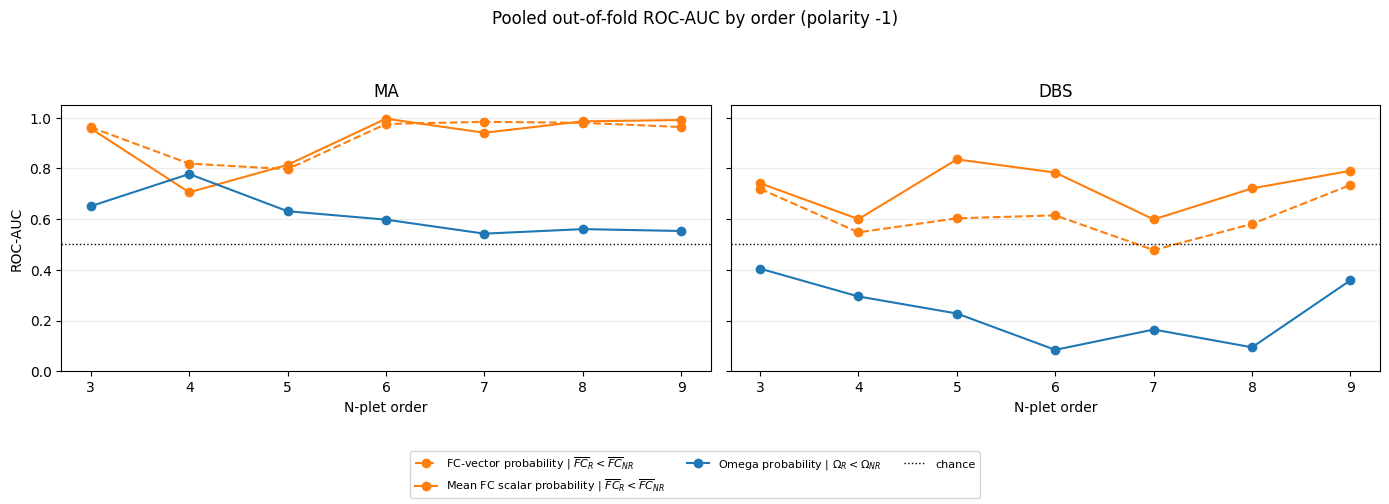

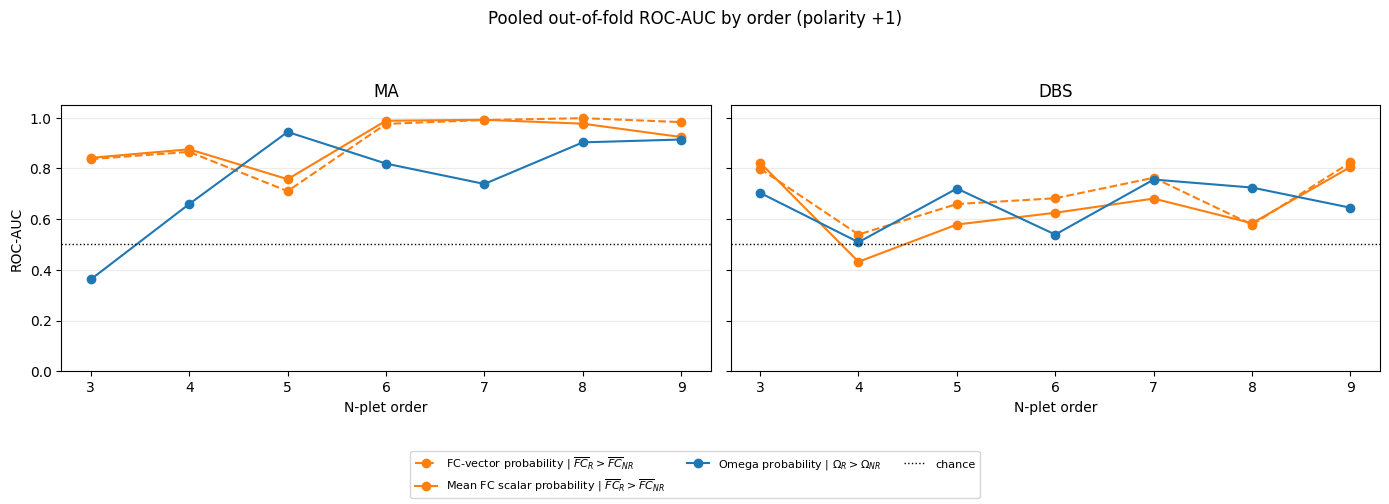

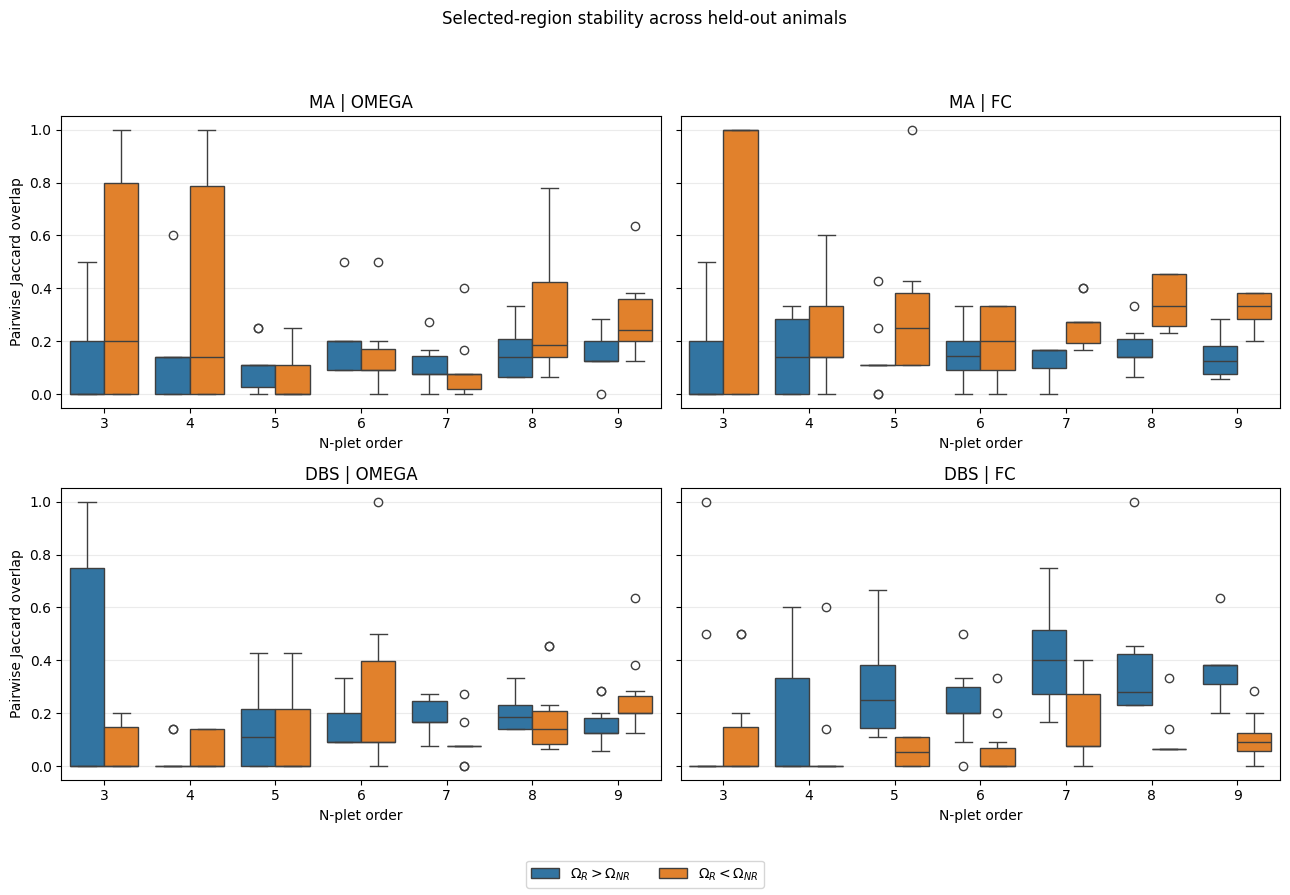

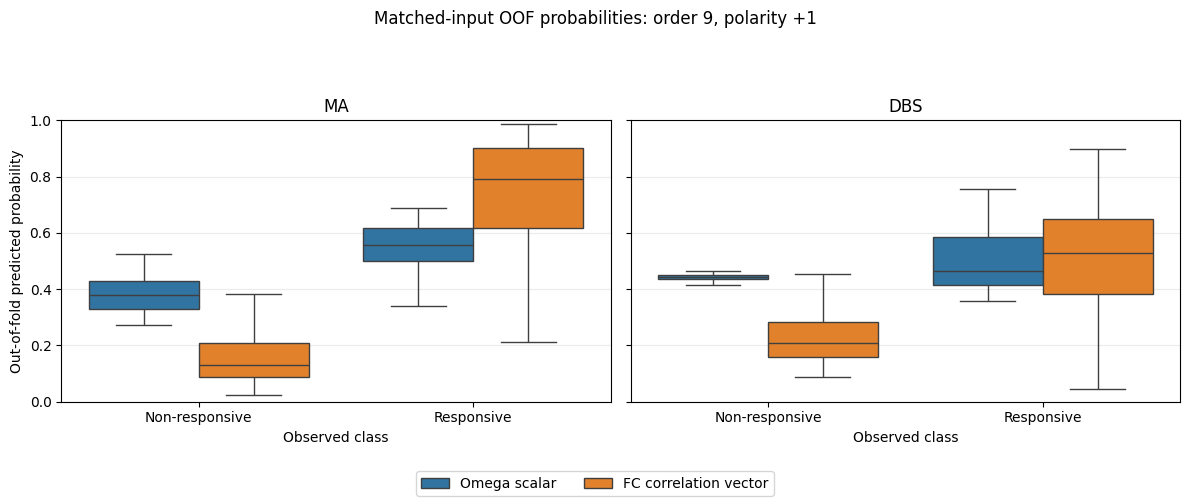

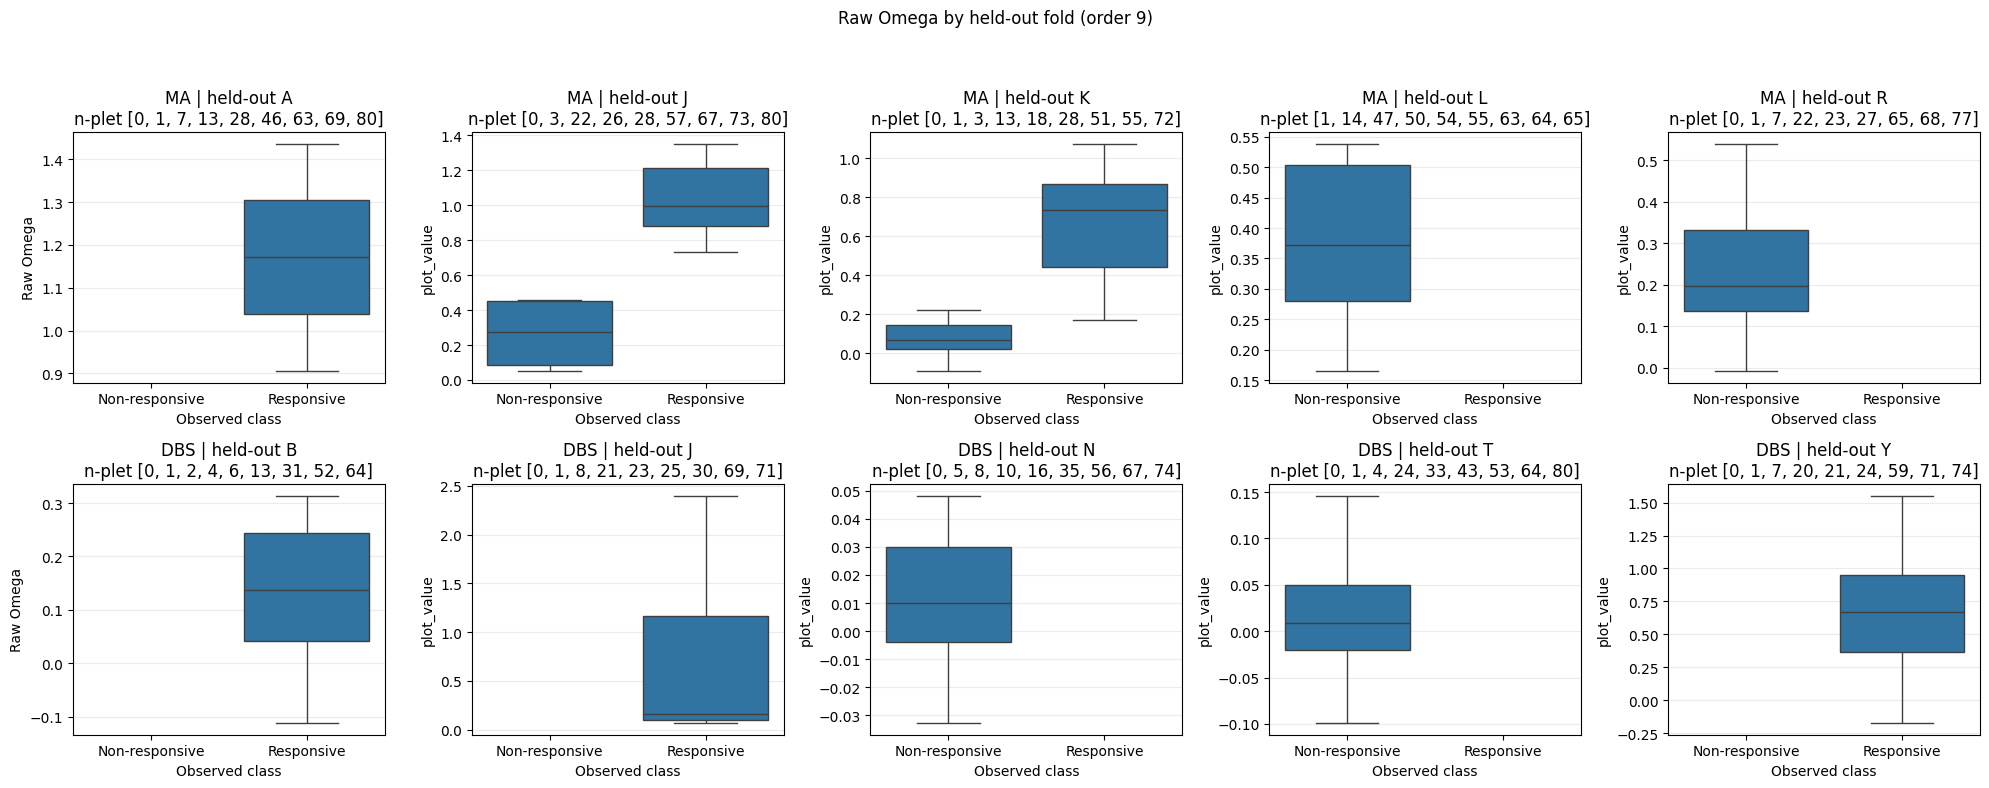

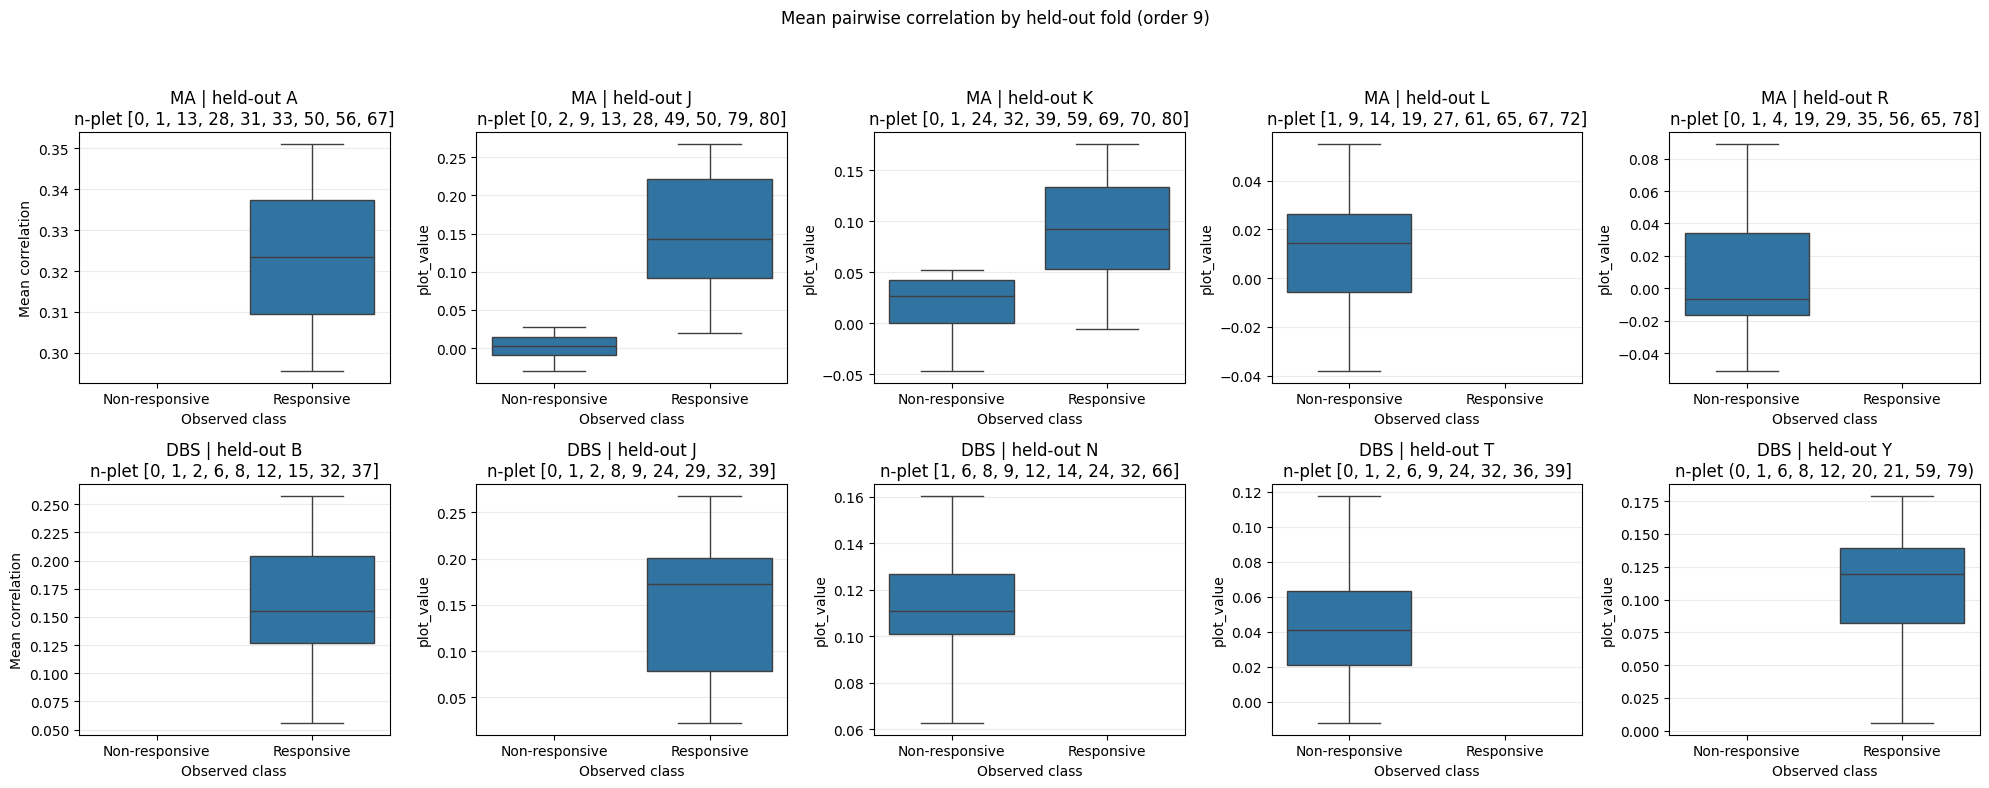

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

measure_colors = {"omega": "tab:blue", "fc": "tab:orange"}
model_linestyles = {"scalar": "-", "pairwise_vector": "--"}
for polarity in (-1, 1):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for dataset, ax in zip(DATASETS, axes):
        subset = metrics.loc[
            (metrics["dataset"] == dataset) & (metrics["polarity"] == polarity)
            & ((metrics["selection_measure"] == "fc")
               | ((metrics["selection_measure"] == "omega") & (metrics["model"] == "scalar")))
        ]
        for (measure, model), group in subset.groupby(
            ["selection_measure", "model"], sort=True,
        ):
            group = group.sort_values("order")
            direction = (
                (r"$\Omega_R > \Omega_{NR}$" if polarity == 1 else r"$\Omega_R < \Omega_{NR}$")
                if measure == "omega" else
                (r"$\overline{FC}_R > \overline{FC}_{NR}$" if polarity == 1
                 else r"$\overline{FC}_R < \overline{FC}_{NR}$")
            )
            model_label = {
                ("omega", "scalar"): "Omega probability",
                ("fc", "scalar"): "Mean FC scalar probability",
                ("fc", "pairwise_vector"): "FC-vector probability",
            }[(measure, model)]
            ax.plot(
                group["order"], group["roc_auc"], marker="o",
                color=measure_colors[measure], linestyle=model_linestyles[model],
                label=f"{model_label} | {direction}",
            )
        ax.axhline(0.5, color="black", linestyle=":", linewidth=1, label="chance")
        ax.set(title=dataset, xlabel="N-plet order", xticks=sorted(metrics["order"].unique()))
        ax.set_ylim(0, 1.05)
        ax.grid(axis="y", alpha=0.25)
    axes[0].set_ylabel("ROC-AUC")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8)
    fig.suptitle(f"Pooled out-of-fold ROC-AUC by order (polarity {polarity:+d})")
    fig.tight_layout(rect=(0, 0.14, 1, 0.93))
    plt.show()

stability = pd.concat([result.stability for result in results.values()], ignore_index=True)
omega_direction = np.where(
    stability["polarity"] == 1, r"$\Omega_R > \Omega_{NR}$", r"$\Omega_R < \Omega_{NR}$",
)
fc_direction = np.where(
    stability["polarity"] == 1,
    r"$\overline{FC}_R > \overline{FC}_{NR}$",
    r"$\overline{FC}_R < \overline{FC}_{NR}$",
)
stability["direction"] = np.where(
    stability["selection_measure"] == "omega", omega_direction, fc_direction,
)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
stability_handles, stability_labels = [], []
for row, dataset in enumerate(DATASETS):
    for column, measure in enumerate(("omega", "fc")):
        ax = axes[row, column]
        subset = stability.loc[
            (stability["dataset"] == dataset)
            & (stability["selection_measure"] == measure)
        ]
        sns.boxplot(
            data=subset, x="order", y="jaccard", hue="direction",
            hue_order=(
                [r"$\Omega_R > \Omega_{NR}$", r"$\Omega_R < \Omega_{NR}$"]
                if measure == "omega" else
                [r"$\overline{FC}_R > \overline{FC}_{NR}$", r"$\overline{FC}_R < \overline{FC}_{NR}$"]
            ), ax=ax,
        )
        if row == 0 and column == 0:
            stability_handles, stability_labels = ax.get_legend_handles_labels()
        ax.set(title=f"{dataset} | {measure.upper()}", xlabel="N-plet order")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(axis="y", alpha=0.25)
        if ax.get_legend() is not None:
            ax.get_legend().remove()
axes[0, 0].set_ylabel("Pairwise Jaccard overlap")
axes[1, 0].set_ylabel("Pairwise Jaccard overlap")
fig.legend(stability_handles, stability_labels, loc="lower center", ncol=2)
fig.suptitle("Selected-region stability across held-out animals")
fig.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.show()

PROBABILITY_ORDER = 9
PROBABILITY_POLARITY = 1
predictions = pd.concat([result.predictions for result in results.values()], ignore_index=True)
matched_models = (
    ((predictions["selection_measure"] == "omega") & (predictions["model"] == "scalar"))
    | ((predictions["selection_measure"] == "fc") & (predictions["model"] == "pairwise_vector"))
)
probability_data = predictions.loc[
    (predictions["order"] == PROBABILITY_ORDER)
    & (predictions["polarity"] == PROBABILITY_POLARITY)
    & matched_models
].copy()
probability_data["predictor"] = np.where(
    probability_data["selection_measure"] == "omega",
    "Omega scalar",
    "FC correlation vector",
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
probability_handles, probability_labels = [], []
for dataset, ax in zip(DATASETS, axes):
    subset = probability_data.loc[probability_data["dataset"] == dataset]
    sns.boxplot(
        data=subset, x="responsive", y="probability", hue="predictor",
        hue_order=["Omega scalar", "FC correlation vector"],
        order=[0, 1], showfliers=False, ax=ax,
    )
    if dataset == DATASETS[0]:
        probability_handles, probability_labels = ax.get_legend_handles_labels()
    ax.set(title=dataset, xlabel="Observed class")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-responsive", "Responsive"])
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
axes[0].set_ylabel("Out-of-fold predicted probability")
fig.legend(probability_handles, probability_labels, loc="lower center", ncol=2)
fig.suptitle(
    f"Matched-input OOF probabilities: order {PROBABILITY_ORDER}, "
    f"polarity {PROBABILITY_POLARITY:+d}"
)
fig.tight_layout(rect=(0, 0.08, 1, 0.9))
plt.show()

raw_omega = predictions.loc[
    (predictions["order"] == PROBABILITY_ORDER)
    & (predictions["polarity"] == PROBABILITY_POLARITY)
    & (predictions["selection_measure"] == "omega")
    & (predictions["model"] == "scalar")
].copy()
raw_omega["plot_value"] = raw_omega["raw_omega"]
mean_fc = predictions.loc[
    (predictions["order"] == PROBABILITY_ORDER)
    & (predictions["polarity"] == PROBABILITY_POLARITY)
    & (predictions["selection_measure"] == "fc")
    & (predictions["model"] == "scalar")
].copy()
mean_fc_values = []
for prediction in mean_fc.itertuples(index=False):
    covariance_stack, scan_metadata = inputs[prediction.dataset]
    matches = np.flatnonzero(
        (scan_metadata["state"].to_numpy() == prediction.state)
        & (scan_metadata["scan_index"].to_numpy() == prediction.scan_index)
    )
    if len(matches) != 1:
        raise ValueError("Could not uniquely align an OOF prediction to its covariance matrix.")
    regions = np.asarray(prediction.nplet, dtype=int)
    covariance = covariance_stack[matches[0]][np.ix_(regions, regions)]
    standard_deviation = np.sqrt(np.diag(covariance))
    correlations = covariance / np.outer(standard_deviation, standard_deviation)
    edges = np.triu_indices(len(regions), k=1)
    mean_fc_values.append(float(correlations[edges].mean()))
mean_fc["plot_value"] = mean_fc_values

for plot_data, plot_title, ylabel in (
    (raw_omega, f"Raw Omega by held-out fold (order {PROBABILITY_ORDER})", "Raw Omega"),
    (mean_fc, f"Mean pairwise correlation by held-out fold (order {PROBABILITY_ORDER})",
     "Mean correlation"),
):
    animals_by_dataset = {
        dataset: sorted(plot_data.loc[plot_data["dataset"] == dataset, "held_out_animal"].unique())
        for dataset in DATASETS
    }
    max_folds = max(len(animals) for animals in animals_by_dataset.values())
    fig, axes = plt.subplots(
        len(DATASETS), max_folds,
        figsize=(4 * max_folds, 4 * len(DATASETS)), squeeze=False,
    )
    for row_index, dataset in enumerate(DATASETS):
        for column, ax in enumerate(axes[row_index]):
            animals = animals_by_dataset[dataset]
            if column >= len(animals):
                ax.set_visible(False)
                continue
            animal = animals[column]
            fold_data = plot_data.loc[
                (plot_data["dataset"] == dataset) & (plot_data["held_out_animal"] == animal)
            ]
            nplet = fold_data["nplet"].iloc[0]
            sns.boxplot(
                data=fold_data, x="responsive", y="plot_value", order=[0, 1],
                showfliers=False, ax=ax,
            )
            ax.set_title(f"{dataset} | held-out {animal}\nn-plet {nplet}")
            ax.set_xlabel("Observed class")
            ax.set_xticks([0, 1])
            ax.set_xticklabels(["Non-responsive", "Responsive"])
            ax.grid(axis="y", alpha=0.25)
        axes[row_index, 0].set_ylabel(ylabel)
    fig.suptitle(plot_title)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

## Feature-set evaluation: each selection with its own family
O, O/S and FC go through the same pipeline, and families are never crossed:

| Selection (training ROC-AUC) | Probability models on the selected n-plet (printed label) |
|---|---|
| O | O scalar (`O scalar`, 1 feature); (TC, DTC) (`O (TC,DTC)`, 2); O gradient (`O gradient`, n) |
| O/S | O/S scalar (`O/S scalar`, 1); (TC, DTC) (`O/S (TC,DTC)`, 2); O/S gradient (`O/S gradient`, n) |
| Mean FC | Mean FC scalar (`FC mean`, 1); every pairwise Fisher-z (`FC vector`, n(n-1)/2; 36 at order 9) |

**Fair comparison:** the primary scalar comparison is Omega versus mean FC, using one feature in each model. The pairwise vector has n(n-1)/2 features and is not a fair comparator for scalar Omega; a fair vector comparison requires a matched high-order feature vector.

**Gradient vector:** the first-order O-information gradient, with one value per region. Column i is Omega(X) - Omega(X without region i), computed with O or O/S to match the selection:
- **Sign:** positive means region i adds redundancy; negative means it adds synergy.
- **Order 3:** removing a region leaves a pair, whose Omega is exactly 0, so all three columns equal the scalar. The gradient only adds information from order 4.

**Why keep (TC, DTC):** it is a linear rescaling of (O, S), and S tracks overall dependence strength. It is kept for comparison with the gradient.

Pipeline:
1. **Selection:** the search cells above choose each fold's n-plet from training animals only, maximizing animal-balanced training ROC-AUC, with identical settings and seeds for all three measures.
2. **Probabilities:** each model is an L2-penalized logistic regression with C=1. Features are standardized with the training animals' (weighted) mean and SD, and the same transform is applied to the held-out animal.
3. **Pooled evaluation:** ROC-AUC and PR-AUC over all held-out scans. Since each scan is predicted by a fold-specific model, these metrics pool scores across folds and should be interpreted with the scale caveat below.
4. **Per-fold evaluation:** ROC-AUC and PR-AUC are defined only when the held-out fold contains both classes; single-class folds remain non-evaluable for these metrics.

Tables are saved as `results/R1_A_loao/<dataset>_features_{predictions,fits,pooled,animal,animal_summary}.csv`.

In [13]:
feature_results = {}
for dataset, (covariances, scans) in inputs.items():
    feature_results[dataset] = evaluate_feature_sets(
        covariances, scans, results[dataset].selections,
        device=DEVICE, batch_size=SETTINGS.batch_size,
        selection_measures=SEARCH_MEASURES,
    )
    save_feature_evaluation(feature_results[dataset], OUTPUT, f'{dataset}_features')

MODEL_LABELS = {
    ('omega', 'omega'): 'O scalar',
    ('omega', 'hoi_vector'): 'O (TC,DTC)',
    ('omega', 'omega_gradient'): 'O gradient',
    ('omega_norm', 'omega'): 'O/S scalar',
    ('omega_norm', 'hoi_vector'): 'O/S (TC,DTC)',
    ('omega_norm', 'omega_gradient'): 'O/S gradient',
    ('fc', 'fc_mean'): 'FC mean',
    ('fc', 'fc_vector'): 'FC vector',
}
MODEL_ORDER = list(MODEL_LABELS.values())

feature_predictions = pd.concat([r.predictions for r in feature_results.values()], ignore_index=True)
feature_pooled = pd.concat([r.pooled for r in feature_results.values()], ignore_index=True)
for frame in (feature_predictions, feature_pooled):
    frame['model_label'] = [
        MODEL_LABELS[(measure, feature_set)]
        for measure, feature_set in zip(frame['selection_measure'], frame['feature_set'])
    ]
print('Models per dataset/polarity/order:', feature_pooled.groupby(['dataset', 'polarity', 'order']).size().unique())

Models per dataset/polarity/order: [8]


### Interpreting pooled OOF metrics
The primary reported metrics are ROC-AUC and PR-AUC, computed from out-of-fold predictions. Each held-out animal is scored by a model fitted without that animal, but pooled metrics compare scores from different fold models. This is especially important in DBS, where each animal contributes only one class: probabilities from different folds may have different scales and intercepts, so pooled AUCs are descriptive rather than a fully scale-calibrated comparison.

Per-fold ROC-AUC and PR-AUC are available only when the held-out fold contains both classes. A single-class fold has undefined ROC-AUC and PR-AUC and is retained as non-evaluable; do not replace these with accuracy or balanced accuracy.

With so few animals, significance would require permutation of animal labels; that is not done here.

In [14]:
TABLE_INDEX = ['dataset', 'polarity', 'order']

print('Pooled out-of-fold ROC-AUC')
roc_auc_table = feature_pooled.pivot_table(
    index=TABLE_INDEX, columns='model_label', values='roc_auc',
).reindex(columns=MODEL_ORDER)
display(roc_auc_table.round(3))

print('Pooled out-of-fold PR-AUC (weighted prevalence 0.5)')
pr_auc_table = feature_pooled.pivot_table(
    index=TABLE_INDEX, columns='model_label', values='pr_auc',
).reindex(columns=MODEL_ORDER)
display(pr_auc_table.round(3))

print('Mean pooled OOF ROC-AUC and PR-AUC over n-plet orders')
mean_metrics_over_orders = (
    feature_pooled.groupby(['dataset', 'polarity', 'model_label'])[['roc_auc', 'pr_auc']]
    .mean().reindex(MODEL_ORDER, level='model_label')
)
display(mean_metrics_over_orders.round(3))

selections_all = pd.concat([r.selections for r in results.values()], ignore_index=True)
selections_all = selections_all.loc[selections_all['selection_measure'].isin(SEARCH_MEASURES)]
training_auc_saturation = (
    selections_all.assign(saturated=selections_all['training_auc'] >= 1 - 1e-9)
    .groupby(['dataset', 'selection_measure', 'polarity'])
    .agg(folds=('saturated', 'size'), saturated=('saturated', 'sum'),
         min_training_auc=('training_auc', 'min'),
         median_training_auc=('training_auc', 'median'))
)
print('Training-AUC saturation of selected n-plets (ties at AUC = 1 are broken arbitrarily)')
display(training_auc_saturation.round(3))

stability_all = pd.concat([r.stability for r in results.values()], ignore_index=True)
selection_stability = (
    stability_all.loc[stability_all['selection_measure'].isin(SEARCH_MEASURES)]
    .pivot_table(index=TABLE_INDEX, columns='selection_measure', values='jaccard')
    [list(SEARCH_MEASURES)]
)
print('Selected-region stability: mean pairwise Jaccard across folds')
display(selection_stability.round(3))

held_out_means = (
    feature_predictions.loc[feature_predictions['feature_set'].isin(['omega', 'fc_mean'])]
    .groupby(['dataset', 'selection_measure', 'polarity', 'order', 'responsive'])['selection_value']
    .mean().unstack('responsive').rename(columns={0: 'mean_NR', 1: 'mean_R'})
)
held_out_means['direction_holds'] = (
    np.sign(held_out_means['mean_R'] - held_out_means['mean_NR'])
    == held_out_means.index.get_level_values('polarity')
)
print('Held-out direction check for the selected scalar measure')
display(held_out_means.round(4))

Pooled out-of-fold ROC-AUC


model_label             O scalar  O (TC,DTC)  O gradient  O/S scalar  \
dataset polarity order                                                 
DBS     -1       3         0.404       0.727       0.395       0.393   
                 4         0.295       0.986       0.294       0.407   
                 5         0.228       0.998       0.193       0.190   
                 6         0.084       0.976       0.136       0.132   
                 7         0.165       1.000       0.437       0.059   
                 8         0.095       0.996       0.322       0.111   
                 9         0.359       1.000       0.399       0.078   
         1       3         0.703       0.967       0.704       0.376   
                 4         0.509       0.845       0.517       0.350   
                 5         0.720       0.936       0.803       0.520   
                 6         0.539       0.937       0.624       0.710   
                 7         0.756       0.988       0.755       0.775   
                 8         0.724       0.981       0.863       0.763   
                 9         0.645       1.000       0.783       0.873   
MA      -1       3         0.651       0.930       0.640       0.617   
                 4         0.778       0.895       0.776       0.834   
                 5         0.631       0.733       0.671       0.683   
                 6         0.598       0.838       0.537       0.739   
                 7         0.542       0.935       0.465       0.768   
                 8         0.560       0.824       0.595       0.765   
                 9         0.553       0.889       0.611       0.582   
         1       3         0.362       0.907       0.363       0.790   
                 4         0.659       0.981       0.669       0.688   
                 5         0.943       0.923       0.919       0.695   
                 6         0.819       0.937       0.818       0.805   
                 7         0.738       0.962       0.768       0.843   
                 8         0.902       0.947       0.909       0.944   
                 9         0.913       0.948       0.944       0.851   

model_label             O/S (TC,DTC)  O/S gradient  FC mean  FC vector  
dataset polarity order                                                  
DBS     -1       3             0.745         0.389    0.741      0.719  
                 4             0.983         0.467    0.600      0.548  
                 5             0.975         0.177    0.835      0.603  
                 6             0.931         0.223    0.783      0.615  
                 7             0.998         0.250    0.599      0.478  
                 8             0.995         0.343    0.721      0.581  
                 9             1.000         0.372    0.790      0.734  
         1       3             0.976         0.376    0.822      0.798  
                 4             0.978         0.393    0.432      0.539  
                 5             0.851         0.561    0.578      0.659  
                 6             0.954         0.660    0.625      0.682  
                 7             0.989         0.837    0.681      0.763  
                 8             0.993         0.810    0.584      0.578  
                 9             0.998         0.773    0.805      0.823  
MA      -1       3             0.776         0.615    0.957      0.962  
                 4             0.905         0.724    0.705      0.818  
                 5             0.887         0.743    0.814      0.797  
                 6             0.963         0.722    0.996      0.975  
                 7             0.909         0.801    0.940      0.983  
                 8             0.920         0.549    0.985      0.979  
                 9             0.923         0.636    0.990      0.963  
         1       3             0.925         0.791    0.841      0.836  
                 4             0.933         0.767    0.875      0.865  
              

Pooled out-of-fold PR-AUC (weighted prevalence 0.5)


model_label             O scalar  O (TC,DTC)  O gradient  O/S scalar  \
dataset polarity order                                                 
DBS     -1       3         0.505       0.822       0.499       0.526   
                 4         0.539       0.987       0.525       0.575   
                 5         0.482       0.998       0.461       0.358   
                 6         0.383       0.981       0.440       0.340   
                 7         0.432       1.000       0.642       0.326   
                 8         0.367       0.996       0.548       0.334   
                 9         0.515       1.000       0.610       0.324   
         1       3         0.785       0.969       0.785       0.530   
                 4         0.698       0.876       0.705       0.558   
                 5         0.777       0.947       0.835       0.644   
                 6         0.717       0.958       0.773       0.773   
                 7         0.833       0.989       0.851       0.805   
                 8         0.837       0.985       0.919       0.795   
                 9         0.780       1.000       0.867       0.877   
MA      -1       3         0.764       0.940       0.759       0.623   
                 4         0.832       0.905       0.829       0.810   
                 5         0.657       0.803       0.693       0.665   
                 6         0.627       0.794       0.554       0.760   
                 7         0.579       0.937       0.497       0.793   
                 8         0.637       0.851       0.649       0.801   
                 9         0.618       0.915       0.703       0.522   
         1       3         0.583       0.922       0.583       0.866   
                 4         0.777       0.982       0.792       0.706   
                 5         0.950       0.933       0.931       0.713   
                 6         0.895       0.943       0.897       0.841   
                 7         0.824       0.968       0.860       0.836   
                 8         0.918       0.952       0.913       0.948   
                 9         0.938       0.957       0.956       0.848   

model_label             O/S (TC,DTC)  O/S gradient  FC mean  FC vector  
dataset polarity order                                                  
DBS     -1       3             0.847         0.524    0.837      0.819  
                 4             0.984         0.605    0.665      0.635  
                 5             0.979         0.360    0.873      0.671  
                 6             0.954         0.369    0.835      0.726  
                 7             0.998         0.377    0.720      0.623  
                 8             0.996         0.406    0.810      0.695  
                 9             1.000         0.469    0.834      0.829  
         1       3             0.977         0.530    0.869      0.851  
                 4             0.981         0.579    0.585      0.663  
                 5             0.920         0.612    0.684      0.722  
                 6             0.958         0.719    0.707      0.749  
                 7             0.990         0.878    0.778      0.827  
                 8             0.993         0.857    0.706      0.713  
                 9             0.998         0.844    0.833      0.863  
MA      -1       3             0.754         0.621    0.970      0.971  
                 4             0.930         0.721    0.690      0.837  
                 5             0.860         0.722    0.870      0.853  
                 6             0.964         0.797    0.996      0.972  
                 7             0.942         0.859    0.944      0.986  
                 8             0.939         0.676    0.987      0.986  
                 9             0.937         0.729    0.989      0.973  
         1       3             0.939         0.863    0.860      0.858  
                 4             0.949         0.817    0.922      0.918  
              

Mean pooled OOF ROC-AUC and PR-AUC over n-plet orders


roc_auc  pr_auc
dataset polarity model_label                  
DBS     -1       O scalar        0.233   0.461
                 O (TC,DTC)      0.955   0.969
                 O gradient      0.311   0.532
                 O/S scalar      0.196   0.398
                 O/S (TC,DTC)    0.947   0.965
                 O/S gradient    0.317   0.444
                 FC mean         0.724   0.796
                 FC vector       0.611   0.714
         1       O scalar        0.657   0.775
                 O (TC,DTC)      0.951   0.961
                 O gradient      0.721   0.819
                 O/S scalar      0.624   0.712
                 O/S (TC,DTC)    0.963   0.974
                 O/S gradient    0.630   0.717
                 FC mean         0.647   0.737
                 FC vector       0.692   0.770
MA      -1       O scalar        0.616   0.673
                 O (TC,DTC)      0.863   0.878
                 O gradient      0.614   0.669
                 O/S scalar      0.712   0.711
                 O/S (TC,DTC)    0.898   0.904
                 O/S gradient    0.684   0.732
                 FC mean         0.912   0.921
                 FC vector       0.925   0.940
         1       O scalar        0.762   0.841
                 O (TC,DTC)      0.944   0.951
                 O gradient      0.770   0.847
                 O/S scalar      0.802   0.823
                 O/S (TC,DTC)    0.959   0.967
                 O/S gradient    0.698   0.748
                 FC mean         0.907   0.924
                 FC vector       0.908   0.923

... (2 outputs left out)

Selected-region stability: mean pairwise Jaccard across folds


selection_measure       omega  omega_norm     fc
dataset polarity order                          
DBS     -1       3      0.060       0.100  0.120
                 4      0.057       0.143  0.074
                 5      0.122       0.087  0.056
                 6      0.245       0.101  0.062
                 7      0.090       0.117  0.173
                 8      0.191       0.118  0.101
                 9      0.256       0.087  0.104
         1       3      0.300       0.020  0.150
                 4      0.029       0.014  0.160
                 5      0.126       0.036  0.286
                 6      0.148       0.166  0.226
                 7      0.181       0.122  0.405
                 8      0.207       0.101  0.373
                 9      0.151       0.148  0.363
MA      -1       3      0.360       0.120  0.600
                 4      0.343       0.162  0.258
                 5      0.058       0.186  0.305
                 6      0.135       0.181  0.192
                 7      0.095       0.374  0.266
                 8      0.289       0.263  0.351
                 9      0.283       0.211  0.327
         1       3      0.110       0.320  0.140
                 4      0.131       0.167  0.143
                 5      0.106       0.067  0.135
                 6      0.186       0.204  0.154
                 7      0.099       0.190  0.132
                 8      0.149       0.131  0.172
                 9      0.151       0.159  0.136

Held-out direction check for the selected scalar measure


responsive                                mean_NR  mean_R  direction_holds
dataset selection_measure polarity order                                  
DBS     fc                -1       3      -0.0556 -0.2182             True
                                   4      -0.0510 -0.0796             True
                                   5      -0.0336 -0.0875             True
                                   6      -0.0307 -0.0790             True
                                   7      -0.0314 -0.0563             True
...                                           ...     ...              ...
MA      omega_norm         1       5       0.0333  0.1277             True
                                   6       0.0547  0.1565             True
                                   7       0.0762  0.1748             True
                                   8       0.0599  0.1835             True
                                   9       0.0558  0.1429             True

[84 rows x 3 columns]

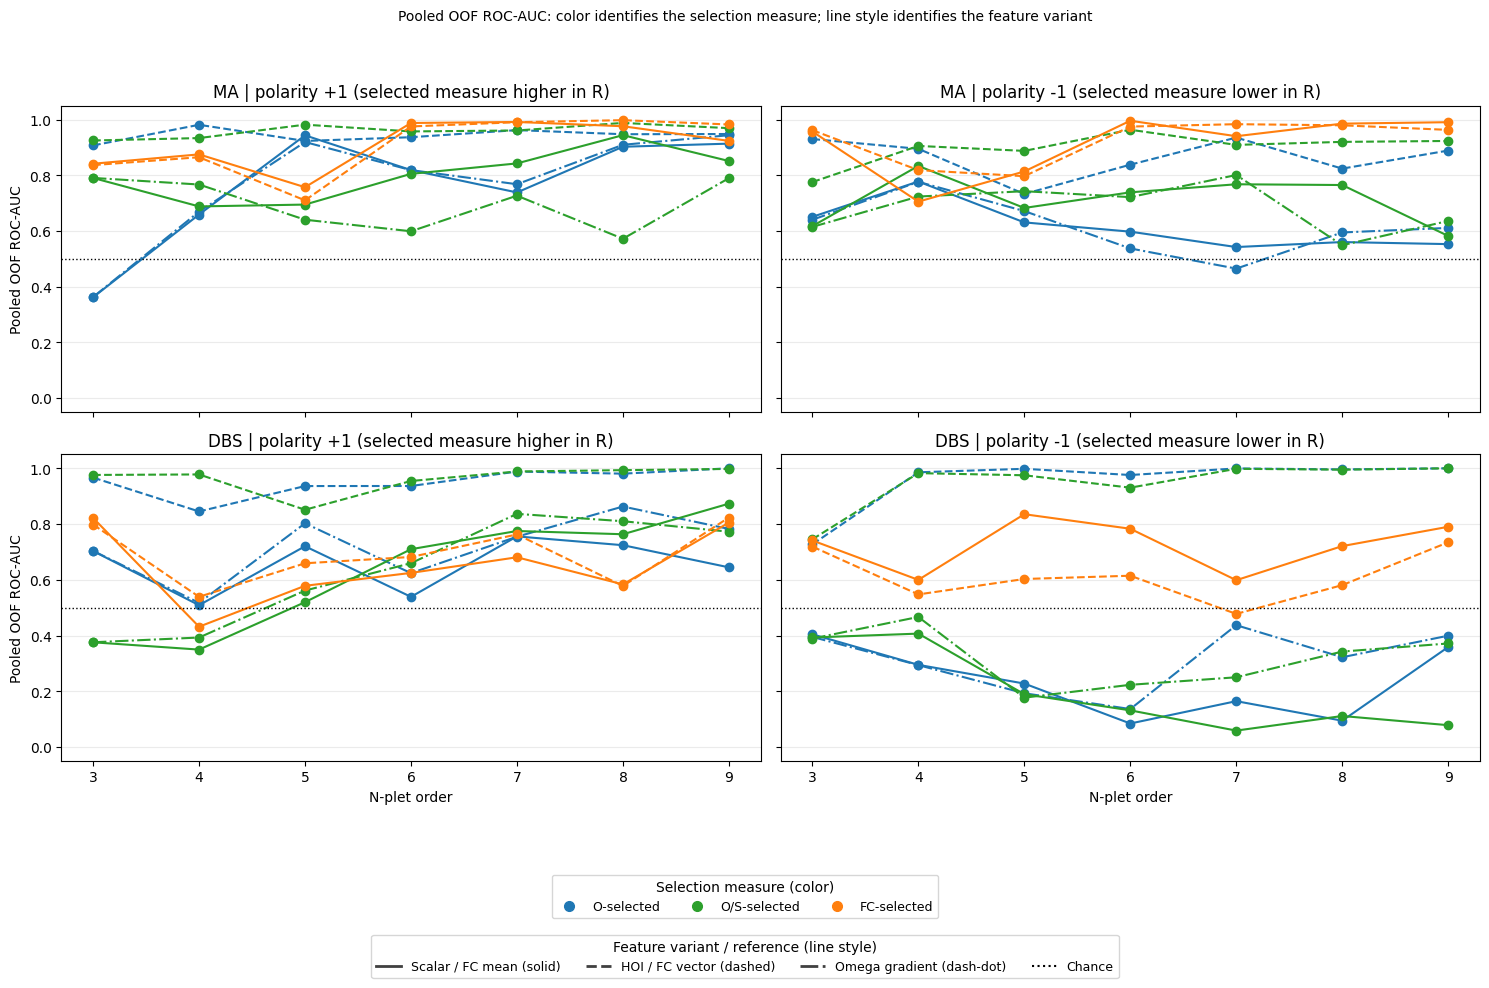

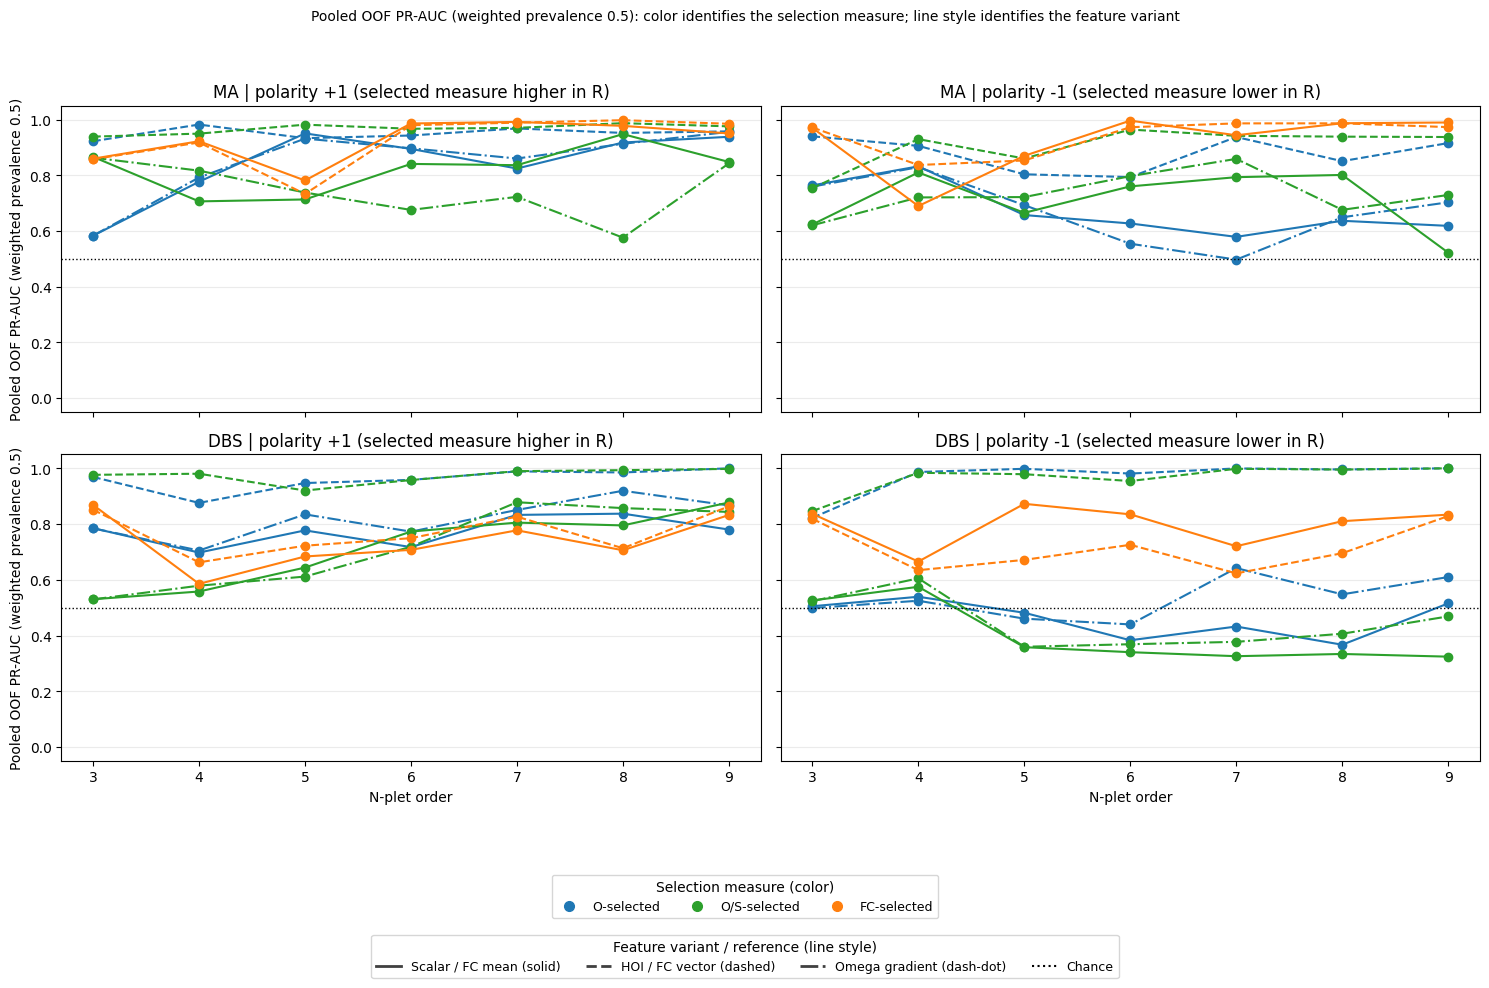

In [15]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

SELECTION_COLORS = {'omega': 'tab:blue', 'omega_norm': 'tab:green', 'fc': 'tab:orange'}
FEATURE_STYLES = {
    'omega': '-', 'fc_mean': '-',
    'hoi_vector': '--', 'fc_vector': '--',
    'omega_gradient': '-.',
}
METRICS = (
    (feature_pooled, 'roc_auc', 'Pooled OOF ROC-AUC'),
    (feature_pooled, 'pr_auc', 'Pooled OOF PR-AUC (weighted prevalence 0.5)'),
)
POLARITIES = (1, -1)
orders = sorted(feature_pooled['order'].unique())

selection_handles = [
    Line2D([], [], color=SELECTION_COLORS[selection], marker='o', linestyle='None',
           markersize=7, label=label)
    for selection, label in (
        ('omega', 'O-selected'),
        ('omega_norm', 'O/S-selected'),
        ('fc', 'FC-selected'),
    )
]
variant_handles = [
    Line2D([], [], color='0.25', linestyle=FEATURE_STYLES[feature_set], linewidth=2,
           label=label)
    for feature_set, label in (
        ('omega', 'Scalar / FC mean (solid)'),
        ('hoi_vector', 'HOI / FC vector (dashed)'),
        ('omega_gradient', 'Omega gradient (dash-dot)'),
    )
]

for table, column, metric_label in METRICS:
    fig, axes = plt.subplots(
        len(DATASETS), len(POLARITIES), figsize=(15, 5 * len(DATASETS)),
        sharex=True, sharey=True, squeeze=False,
    )
    for row, dataset in enumerate(DATASETS):
        for col, polarity in enumerate(POLARITIES):
            ax = axes[row, col]
            subset = table.loc[(table['dataset'] == dataset) & (table['polarity'] == polarity)]
            for (selection, feature_set), label in MODEL_LABELS.items():
                color = SELECTION_COLORS[selection]
                group = subset.loc[
                    (subset['selection_measure'] == selection)
                    & (subset['feature_set'] == feature_set)
                ].sort_values('order')
                ax.plot(
                    group['order'], group[column], marker='o', label=label, color=color,
                    linestyle=FEATURE_STYLES[feature_set],
                )
            ax.axhline(0.5, color='black', linestyle=':', linewidth=1)
            direction = 'selected measure higher in R' if polarity == 1 else 'selected measure lower in R'
            ax.set(title=f'{dataset} | polarity {polarity:+d} ({direction})',
                   xticks=orders, ylim=(-0.05, 1.05))
            if row == len(DATASETS) - 1:
                ax.set_xlabel('N-plet order')
            if col == 0:
                ax.set_ylabel(metric_label)
            ax.grid(axis='y', alpha=0.25)
    fig.legend(
        handles=selection_handles, loc='lower center', bbox_to_anchor=(0.5, 0.065),
        ncol=3, fontsize=9, title='Selection measure (color)',
    )
    fig.legend(
        handles=variant_handles + [Line2D([], [], color='black', linestyle=':', label='Chance')],
        loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=4, fontsize=9,
        title='Feature variant / reference (line style)',
    )
    fig.suptitle(
        f'{metric_label}: color identifies the selection measure; line style identifies the feature variant',
        fontsize=10,
    )
    fig.tight_layout(rect=(0, 0.17, 1, 0.95))
    plt.show()